In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [2]:
df = pd.read_csv(
    "AI_Fresher_Recruitment_ML_Dataset.csv"
)

print("Dataset shape:", df.shape)
print("Unique candidates:", df["Candidate ID"].nunique())

print("\nTarget distribution:")
print(df["Shortlisted"].value_counts())

print("\nTarget percentages:")
print(
    df["Shortlisted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dataset shape: (16508, 41)
Unique candidates: 10000

Target distribution:
Shortlisted
0    16299
1      209
Name: count, dtype: int64

Target percentages:
Shortlisted
0    98.73
1     1.27
Name: proportion, dtype: float64


In [3]:
target = "Shortlisted"

# Columns that must not be used as model inputs
leakage_columns = [
    "Recruitment_Score",
    "Rank",
    "Shortlist Limit",
    "Shortlisted"
]

# Identifiers are not candidate qualifications
identifier_columns = [
    "Candidate ID",
    "Application ID",
    "Job ID"
]

drop_columns = leakage_columns + identifier_columns

X = df.drop(
    columns=drop_columns,
    errors="ignore"
)

y = df[target]

groups = df["Candidate ID"]

print("Number of features:", X.shape[1])
print("\nFeatures:")
print(X.columns.tolist())

Number of features: 34

Features:
['Job Role', 'Degree', 'Specialization', 'CGPA', 'Class 10 Percentage', 'Class 12 Percentage', 'Backlogs', 'Skills', 'Number of Projects', 'Projects', 'Number of Internships', 'Internships', 'Number of Certifications', 'Certifications', 'Number of Achievements', 'Achievements', 'Number of Openings', 'Required Skills', 'Preferred Degree', 'Minimum CGPA', 'CGPA_Score', 'CGPA_Eligible', 'CGPA_Gap', 'Degree_Match', 'Skill_Match', 'Project_Count', 'Internship_Count', 'Certification_Count', 'Achievement_Count', 'Backlog_Score', 'Project_Score', 'Internship_Score', 'Certification_Score', 'Achievement_Score']


In [4]:
# One label per candidate, used only for stratified splitting
candidate_info = (
    df.groupby("Candidate ID")["Shortlisted"]
    .max()
    .reset_index()
)

train_candidates, test_candidates = train_test_split(
    candidate_info["Candidate ID"],
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=candidate_info["Shortlisted"]
)

train_candidates = set(train_candidates)
test_candidates = set(test_candidates)

train_val_df = df[
    df["Candidate ID"].isin(train_candidates)
].copy()

test_df = df[
    df["Candidate ID"].isin(test_candidates)
].copy()

# Remove all leakage columns and identifiers consistently
X_train_val = train_val_df.drop(
    columns=drop_columns,
    errors="ignore"
)

y_train_val = train_val_df[target]

groups_train_val = train_val_df["Candidate ID"]

X_test = test_df.drop(
    columns=drop_columns,
    errors="ignore"
)

y_test = test_df[target]

print("Training/validation applications:", len(X_train_val))
print("Testing applications:", len(X_test))

print(
    "Candidates shared between sets:",
    len(
        set(train_val_df["Candidate ID"])
        & set(test_df["Candidate ID"])
    )
)

print("\nTraining positive rate:", round(y_train_val.mean(), 4))
print("Test positive rate:", round(y_test.mean(), 4))

Training/validation applications: 14039
Testing applications: 2469
Candidates shared between sets: 0

Training positive rate: 0.0128
Test positive rate: 0.0117


In [5]:
categorical_features = X_train_val.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X_train_val.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['CGPA', 'Class 10 Percentage', 'Class 12 Percentage', 'Backlogs', 'Number of Projects', 'Number of Internships', 'Number of Certifications', 'Number of Achievements', 'Number of Openings', 'Minimum CGPA', 'CGPA_Score', 'CGPA_Eligible', 'CGPA_Gap', 'Degree_Match', 'Skill_Match', 'Project_Count', 'Internship_Count', 'Certification_Count', 'Achievement_Count', 'Backlog_Score', 'Project_Score', 'Internship_Score', 'Certification_Score', 'Achievement_Score']
Categorical features: ['Job Role', 'Degree', 'Specialization', 'Skills', 'Projects', 'Internships', 'Certifications', 'Achievements', 'Required Skills', 'Preferred Degree']


In [6]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

In [7]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

In [8]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []
oof_probabilities = {
    name: np.full(len(X_train_val), np.nan)
    for name in models
}

for fold, (train_idx, val_idx) in enumerate(
    cv.split(
        X_train_val,
        y_train_val,
        groups=groups_train_val
    ),
    start=1
):
    X_fold_train = X_train_val.iloc[train_idx]
    y_fold_train = y_train_val.iloc[train_idx]

    X_fold_val = X_train_val.iloc[val_idx]
    y_fold_val = y_train_val.iloc[val_idx]

    for name, model in models.items():

        pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("classifier", model)
            ]
        )

        pipeline.fit(
            X_fold_train,
            y_fold_train
        )

        probabilities = pipeline.predict_proba(
            X_fold_val
        )[:, 1]

        oof_probabilities[name][val_idx] = probabilities

        ap = average_precision_score(
            y_fold_val,
            probabilities
        )

        cv_results.append({
            "Model": name,
            "Fold": fold,
            "Average Precision": ap
        })

        print(
            f"Fold {fold} | {name} | AP = {ap:.4f}"
        )

cv_results_df = pd.DataFrame(cv_results)

Fold 1 | Logistic Regression | AP = 0.6890
Fold 1 | Random Forest | AP = 0.4339
Fold 1 | Extra Trees | AP = 0.4602
Fold 2 | Logistic Regression | AP = 0.7300
Fold 2 | Random Forest | AP = 0.4279
Fold 2 | Extra Trees | AP = 0.4071
Fold 3 | Logistic Regression | AP = 0.8149
Fold 3 | Random Forest | AP = 0.5573
Fold 3 | Extra Trees | AP = 0.5813
Fold 4 | Logistic Regression | AP = 0.8090
Fold 4 | Random Forest | AP = 0.4265
Fold 4 | Extra Trees | AP = 0.4991
Fold 5 | Logistic Regression | AP = 0.8072
Fold 5 | Random Forest | AP = 0.5184
Fold 5 | Extra Trees | AP = 0.5404


In [9]:
cv_summary = (
    cv_results_df
    .groupby("Model")["Average Precision"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .rename(columns={
        "mean": "Mean AP",
        "std": "AP Standard Deviation"
    })
)

display(cv_summary.round(4))

,Mean AP,AP Standard Deviation
Model,,
Logistic Regression,0.7700,0.0572
Extra Trees,0.4976,0.0679
Random Forest,0.4728,0.0610


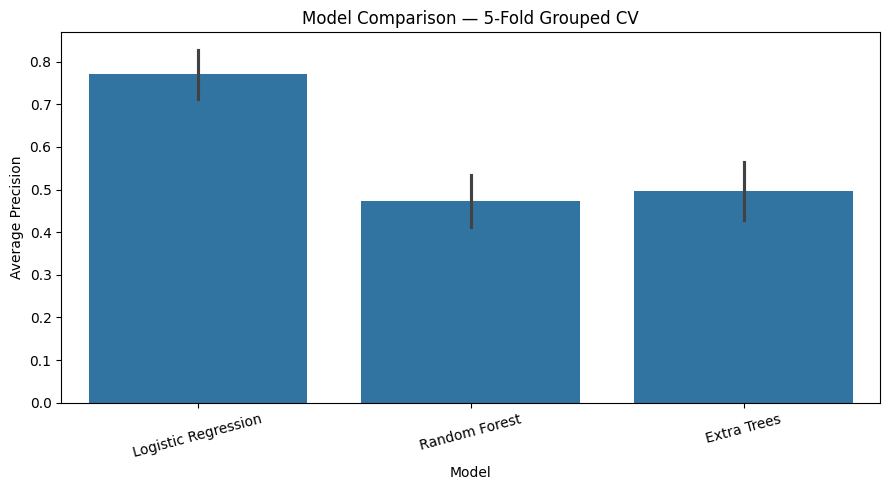

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Average Precision",
    errorbar="sd"
)

plt.title("Model Comparison — 5-Fold Grouped CV")
plt.ylabel("Average Precision")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [11]:
best_model_name = cv_summary["Mean AP"].idxmax()

print("Best model:", best_model_name)
print(
    "Mean CV Average Precision:",
    round(cv_summary.loc[best_model_name, "Mean AP"], 4)
)

Best model: Logistic Regression
Mean CV Average Precision: 0.77


In [12]:
oof_probs = oof_probabilities[best_model_name]

assert not np.isnan(oof_probs).any(), (
    "Some applications did not receive "
    "out-of-fold predictions."
)

precision, recall, thresholds = precision_recall_curve(
    y_train_val,
    oof_probs
)

# The final precision and recall points have no matching threshold.
precision_t = precision[:-1]
recall_t = recall[:-1]

f1_values = (
    2 * precision_t * recall_t
    / (precision_t + recall_t + 1e-12)
)

best_threshold_index = np.argmax(f1_values)

best_threshold = thresholds[best_threshold_index]

print("Selected threshold:", round(best_threshold, 4))
print("CV precision at threshold:", round(
    precision_t[best_threshold_index], 4
))
print("CV recall at threshold:", round(
    recall_t[best_threshold_index], 4
))
print("CV F1-score at threshold:", round(
    f1_values[best_threshold_index], 4
))

Selected threshold: 0.8762
CV precision at threshold: 0.7216
CV recall at threshold: 0.7056
CV F1-score at threshold: 0.7135


In [13]:
best_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", models[best_model_name])
    ]
)

best_pipeline.fit(
    X_train_val,
    y_train_val
)

test_probabilities = best_pipeline.predict_proba(
    X_test
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

In [14]:
test_metrics = {
    "Average Precision": average_precision_score(
        y_test,
        test_probabilities
    ),
    "Precision": precision_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test,
        test_predictions
    )
}

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=[
            "Not Shortlisted",
            "Shortlisted"
        ],
        zero_division=0
    )
)

Average Precision: 0.6263
Precision: 0.4722
Recall: 0.5862
F1-score: 0.5231
Balanced Accuracy: 0.7892

Classification Report:

                 precision    recall  f1-score   support

Not Shortlisted       1.00      0.99      0.99      2440
    Shortlisted       0.47      0.59      0.52        29

       accuracy                           0.99      2469
      macro avg       0.73      0.79      0.76      2469
   weighted avg       0.99      0.99      0.99      2469



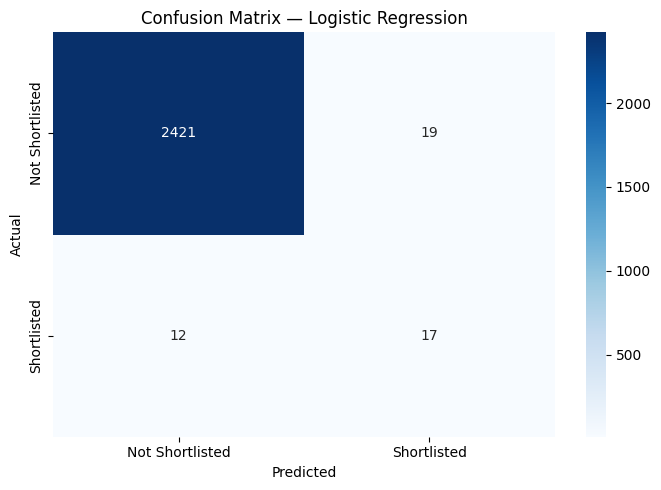

In [15]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Shortlisted",
        "Shortlisted"
    ],
    yticklabels=[
        "Not Shortlisted",
        "Shortlisted"
    ]
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

cv_tuning = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv_tuning,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(
    X_train_val,
    y_train_val,
    groups=groups_train_val
)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation AP:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters:
{'classifier__C': 1, 'classifier__class_weight': None}

Best cross-validation AP:
0.7747


In [16]:
import joblib

model_artifact = {
    "pipeline": best_pipeline,
    "model_name": best_model_name,
    "threshold": float(best_threshold),
    "feature_columns": X_train_val.columns.tolist(),
    "target": target
}

joblib.dump(
    model_artifact,
    "fresher_recruitment_model.joblib"
)

print("Model saved successfully.")

Model saved successfully.
